In [25]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams["font.family"] = "Times New Roman"

In [26]:
df = pd.read_csv("../data/nyc_2024_data_cleaned.csv")
# print(df.shape)
# print(df.head())
print(df.dtypes)

primary_property_type_self            str
year_built                          int64
number_of_buildings                 int64
occupancy                           int64
site_eui_kbtu_ft                  float64
medical_office_gross_floor        float64
medical_office_number_of          float64
medical_office_number_of_1        float64
medical_office_number_of_2        float64
medical_office_percent_that       float64
medical_office_percent_that_1     float64
medical_office_weekly             float64
k_12_school_gross_floor_area      float64
multifamily_housing_government        str
multifamily_housing_gross         float64
multifamily_housing_number_1      float64
multifamily_housing_number_2      float64
multifamily_housing_number_3      float64
multifamily_housing_percent       float64
multifamily_housing_percent_1     float64
multifamily_housing_total_1       float64
multifamily_housing_number_5      float64
multifamily_housing_number_7      float64
multifamily_housing_resident      

***Target Variable***

In [27]:
y = df["site_eui_kbtu_ft"]
print(y.describe())

count     19051.000000
mean        128.129269
std        2341.809912
min           0.000000
25%          49.200000
50%          68.200000
75%          89.500000
max      251650.000000
Name: site_eui_kbtu_ft, dtype: float64


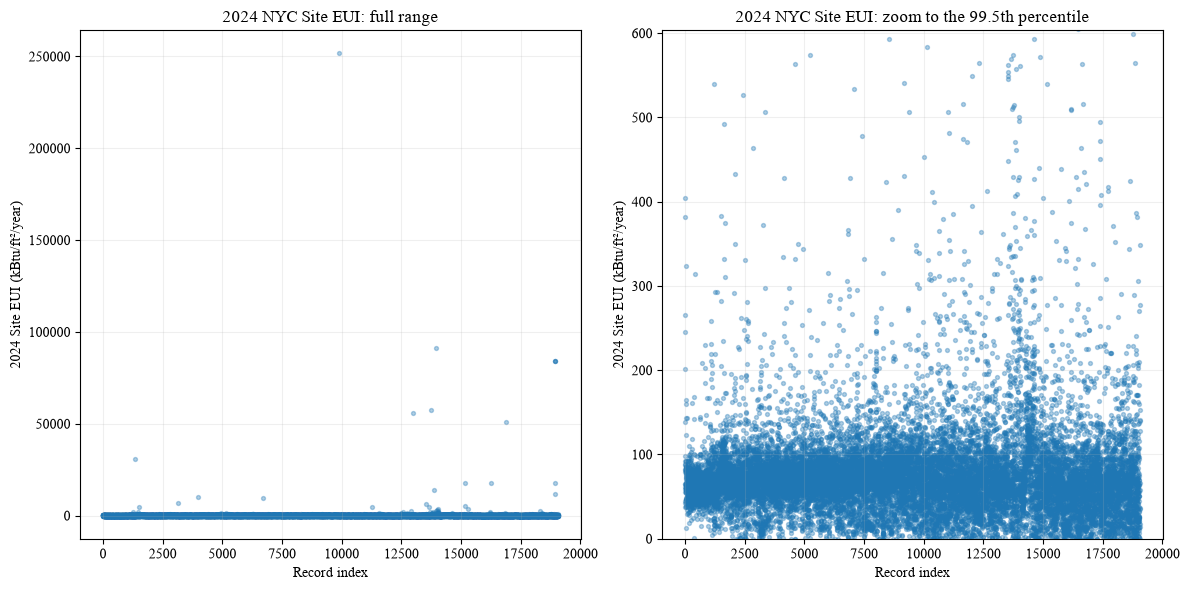

In [28]:
# Plot Site EUI against the record index
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax in axes:
    ax.scatter(y.index, y, s=8, alpha=0.35)
    ax.set_xlabel("Record index")
    ax.set_ylabel("2024 Site EUI (kBtu/ft²/year)")
    ax.grid(alpha=0.2)

axes[0].set_title("2024 NYC Site EUI: full range")

# Zoom the display only; no records are removed
axes[1].set_ylim(0, y.quantile(0.995))
axes[1].set_title("2024 NYC Site EUI: zoom to the 99.5th percentile")

plt.tight_layout()
plt.savefig("../figures/2024_nyc_site_eui_scatter_do_not_use_this.png", dpi=300)
plt.show()

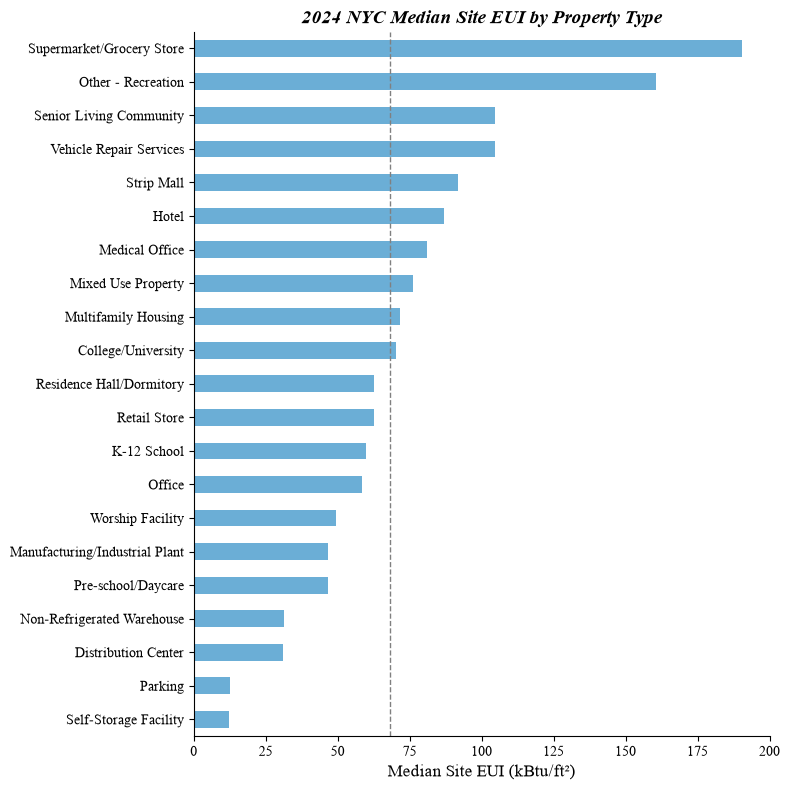

In [29]:
counts = df["primary_property_type_self"].value_counts()
top_types = counts[counts >= 100].index

medians = (
    df[df["primary_property_type_self"].isin(top_types)]
      .groupby("primary_property_type_self")["site_eui_kbtu_ft"]
      .median()
      .sort_values()
)

ax = medians.plot.barh(figsize=(8, 8), color="#6baed6")
ax.axvline(df["site_eui_kbtu_ft"].median(), color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Median Site EUI (kBtu/ft²)", fontsize=12)
ax.set_ylabel("", fontsize=12)
ax.set_title("2024 NYC Median Site EUI by Property Type", fontsize=14, fontweight="bold", style="italic")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../figures/2024_nyc_median_site_eui_by_property_type.png", dpi=300)
plt.show()

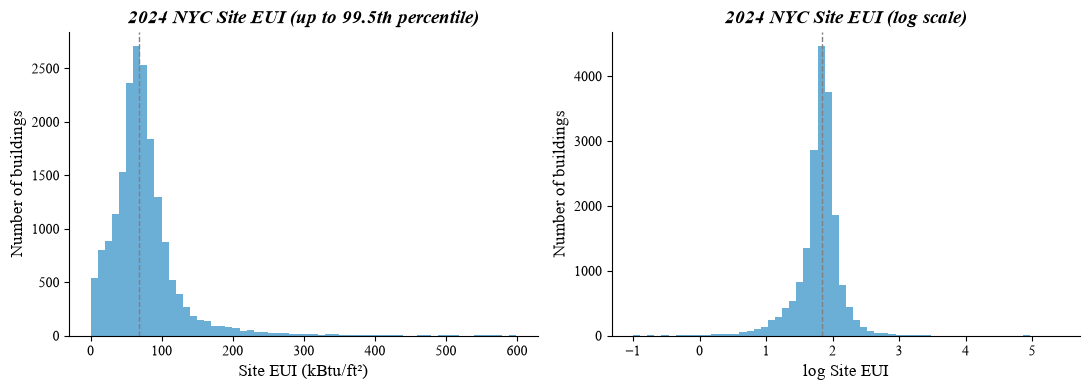

count     19051.000000
mean        128.129269
std        2341.809912
min           0.000000
25%          49.200000
50%          68.200000
75%          89.500000
max      251650.000000
Name: site_eui_kbtu_ft, dtype: float64
Skewness: 77.63


In [30]:
import numpy as np

eui = df["site_eui_kbtu_ft"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Raw scale (cut at the 99th percentile so the tail doesn't flatten everything)
axes[0].hist(eui[eui <= eui.quantile(0.995)], bins=60, color="#6baed6")
axes[0].axvline(eui.median(), color="gray", linestyle="--", linewidth=1)
axes[0].set_title("2024 NYC Site EUI (up to 99.5th percentile)", fontsize=14, fontweight="bold", style="italic")
axes[0].set_xlabel("Site EUI (kBtu/ft²)", fontsize=12)
axes[0].set_ylabel("Number of buildings", fontsize=12)

# Log scale
axes[1].hist(np.log10(eui[eui > 0]), bins=60, color="#6baed6")
axes[1].axvline(np.log10(eui.median()), color="gray", linestyle="--", linewidth=1)
axes[1].set_title("2024 NYC Site EUI (log scale)", fontsize=14, fontweight="bold", style="italic")
axes[1].set_xlabel("log Site EUI", fontsize=12)
axes[1].set_ylabel("Number of buildings", fontsize=12)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("../figures/2024_nyc_site_eui_histograms_do_not_use_this.png", dpi=300)
plt.show()

print(eui.describe())
print(f"Skewness: {eui.skew():.2f}")

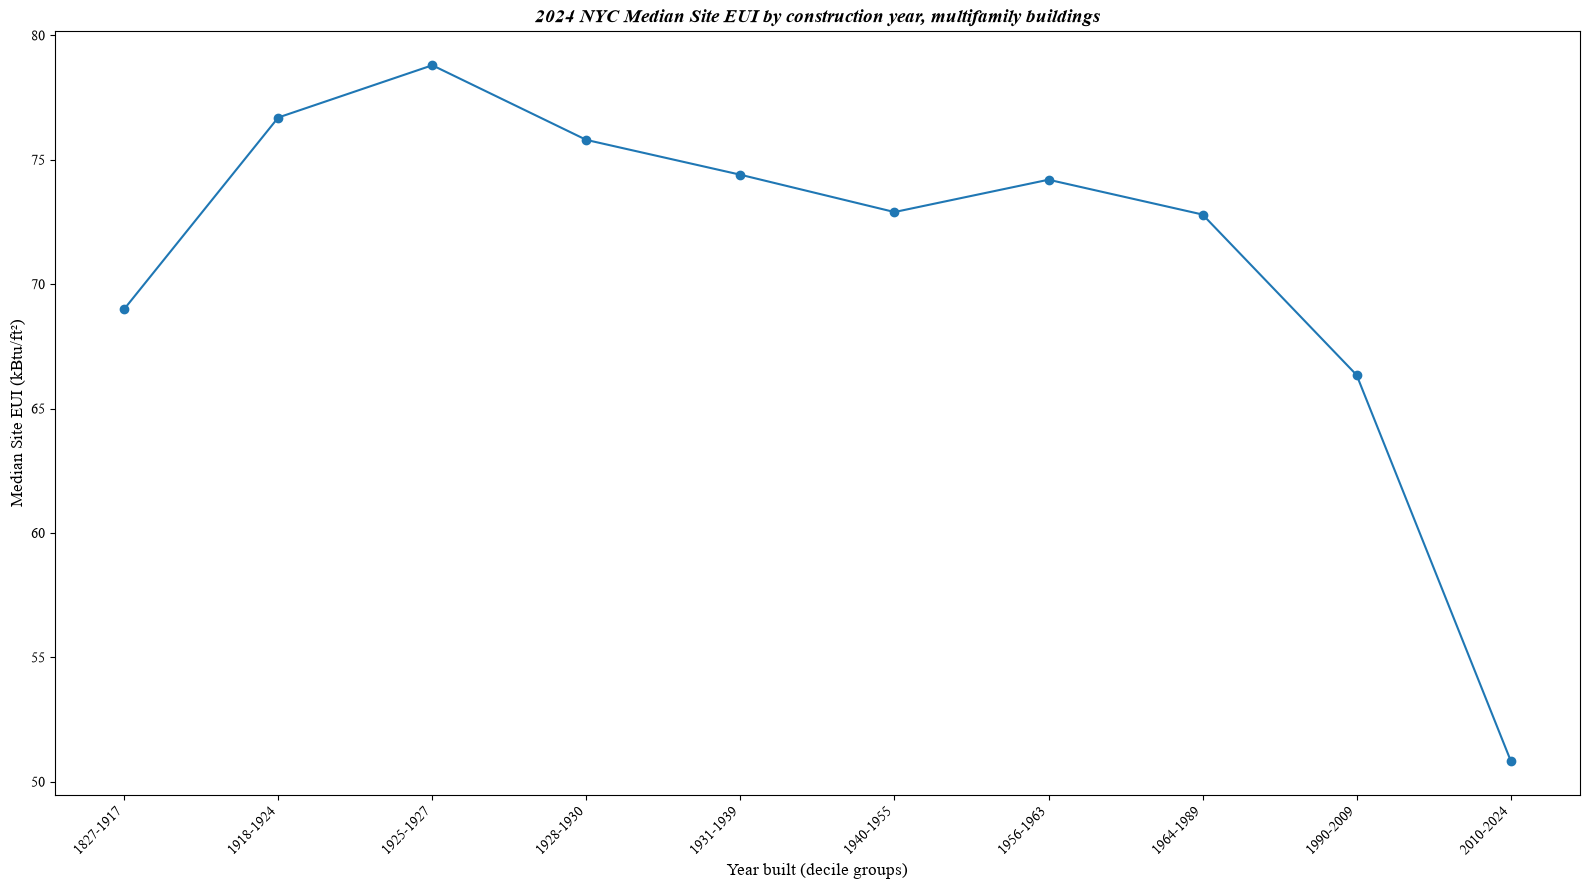

In [31]:
mf = df[df["primary_property_type_self"] == "Multifamily Housing"]
bins = pd.qcut(mf["year_built"], q=10, duplicates="drop")
binned = mf.groupby(bins, observed=True)["site_eui_kbtu_ft"].median()
labels = [f"{int(i.left) + 1}-{int(i.right)}" for i in binned.index]

ax = binned.plot(marker="o", figsize=(16, 9))
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_xlabel("Year built (decile groups)", fontsize=12)
ax.set_ylabel("Median Site EUI (kBtu/ft²)", fontsize=12)
ax.set_title("2024 NYC Median Site EUI by construction year, multifamily buildings", fontsize=14, fontweight="bold", style="italic")
plt.tight_layout()
plt.savefig("../figures/2024_nyc_median_Site_EUI_By_Year_Built.png", dpi=300)
plt.show()